In [1]:
import sys
print(sys.executable)

from sklearn.linear_model import LinearRegression
print("LinearRegression works in Jupyter")

c:\Users\ASUS\anaconda3\python.exe
LinearRegression works in Jupyter


In [2]:
import pandas as pd

# Load SmartQueue dataset
df = pd.read_csv("../data/raw/queue_data.csv")

# Display first 5 rows
df.head()

,queue_length,active_counters,avg_service_time,service_type,hour,day_of_week,is_peak_hour,waiting_time
0,38,4,3.77,Enquiry,17,4,0,34.08
1,28,2,4.15,ID Card,15,3,1,71.41
2,14,5,8.43,Enquiry,16,6,1,29.05
3,7,1,2.35,Scholarship,11,3,1,30.32
4,20,2,9.94,Fee Payment,9,0,0,109.95


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (5000, 8)

Column names:
['queue_length', 'active_counters', 'avg_service_time', 'service_type', 'hour', 'day_of_week', 'is_peak_hour', 'waiting_time']


In [3]:
print("Data types and information:")
df.info()

Data types and information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   queue_length      5000 non-null   int64  
 1   active_counters   5000 non-null   int64  
 2   avg_service_time  5000 non-null   float64
 3   service_type      5000 non-null   str    
 4   hour              5000 non-null   int64  
 5   day_of_week       5000 non-null   int64  
 6   is_peak_hour      5000 non-null   int64  
 7   waiting_time      5000 non-null   float64
dtypes: float64(2), int64(5), str(1)
memory usage: 372.0 KB


In [4]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
queue_length        0
active_counters     0
avg_service_time    0
service_type        0
hour                0
day_of_week         0
is_peak_hour        0
waiting_time        0
dtype: int64


In [5]:
df.describe()

,queue_length,active_counters,avg_service_time,hour,day_of_week,is_peak_hour,waiting_time
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.201400,2.970200,5.982432,12.939000,3.030600,0.556000,63.961928
std,11.788818,1.420322,2.294337,2.557379,1.987172,0.496904,60.523900
min,0.000000,1.000000,2.000000,9.000000,0.000000,0.000000,1.000000
25%,10.000000,2.000000,4.020000,11.000000,1.000000,0.000000,24.627500
50%,20.000000,3.000000,5.950000,13.000000,3.000000,1.000000,45.120000
75%,31.000000,4.000000,7.990000,15.000000,5.000000,1.000000,79.897500
max,40.000000,5.000000,10.000000,17.000000,6.000000,1.000000,404.160000


In [5]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


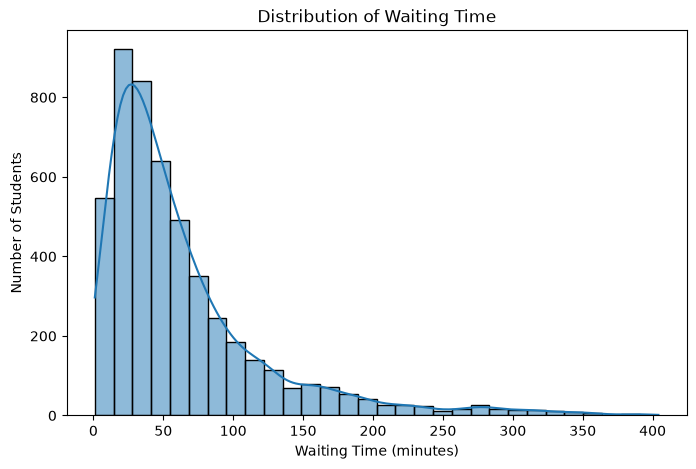

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(df["waiting_time"], bins=30, kde=True)

plt.title("Distribution of Waiting Time")
plt.xlabel("Waiting Time (minutes)")
plt.ylabel("Number of Students")

plt.show()

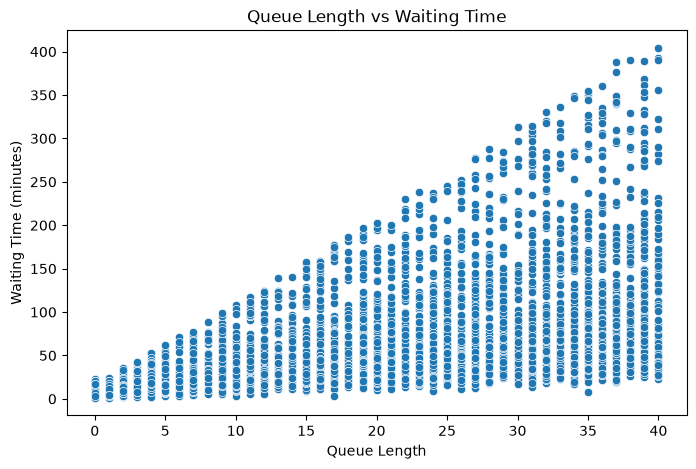

In [7]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="queue_length",
    y="waiting_time"
)

plt.title("Queue Length vs Waiting Time")
plt.xlabel("Queue Length")
plt.ylabel("Waiting Time (minutes)")

plt.show()

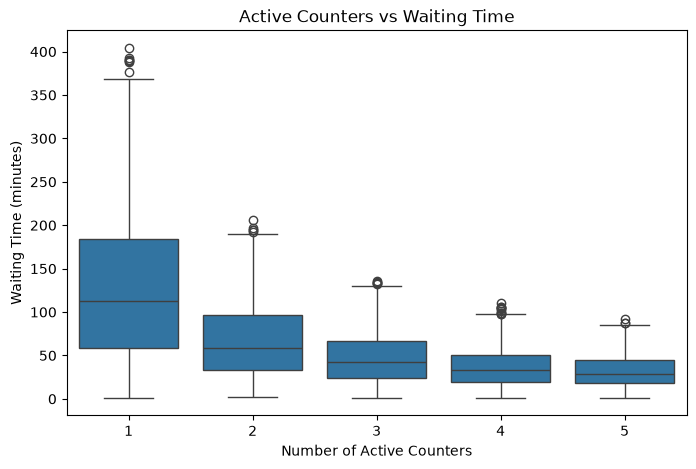

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="active_counters",
    y="waiting_time"
)

plt.title("Active Counters vs Waiting Time")
plt.xlabel("Number of Active Counters")
plt.ylabel("Waiting Time (minutes)")

plt.show()

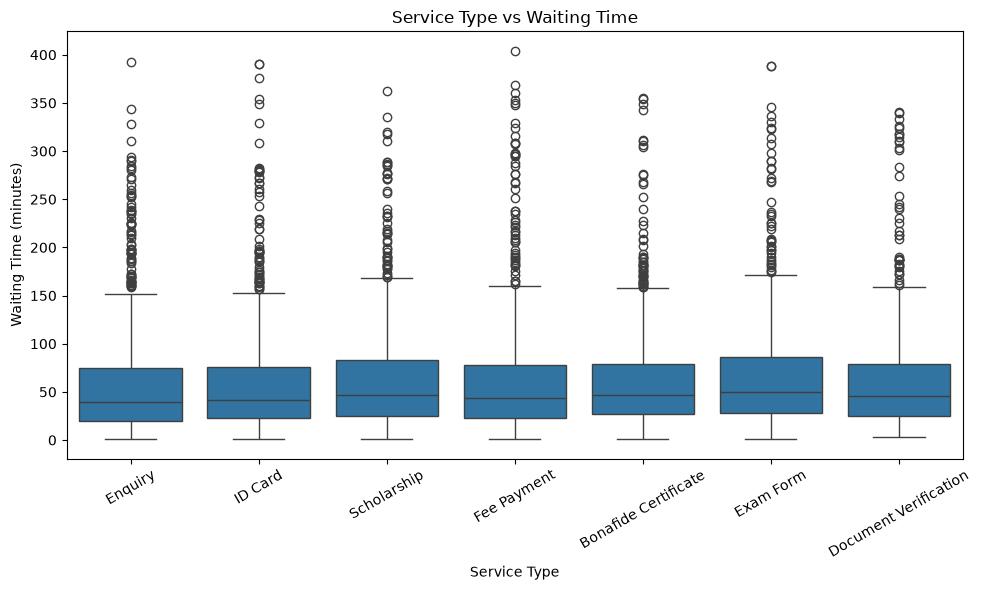

In [9]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="service_type",
    y="waiting_time"
)

plt.title("Service Type vs Waiting Time")
plt.xlabel("Service Type")
plt.ylabel("Waiting Time (minutes)")

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

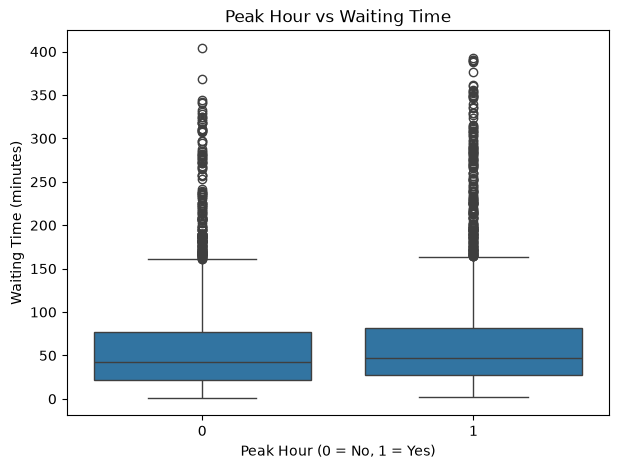

In [10]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="is_peak_hour",
    y="waiting_time"
)

plt.title("Peak Hour vs Waiting Time")
plt.xlabel("Peak Hour (0 = No, 1 = Yes)")
plt.ylabel("Waiting Time (minutes)")

plt.show()

In [11]:
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Calculate correlation
correlation = numeric_df.corr()

# Display correlation with waiting time
print(correlation["waiting_time"].sort_values(ascending=False))

waiting_time        1.000000
queue_length        0.536015
avg_service_time    0.365373
is_peak_hour        0.044760
day_of_week         0.010587
hour                0.008648
active_counters    -0.530308
Name: waiting_time, dtype: float64


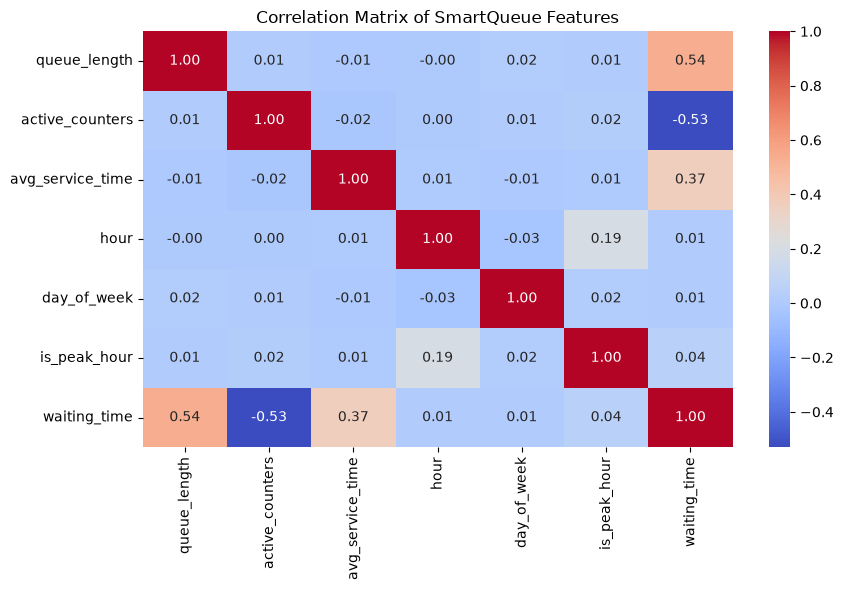

In [12]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of SmartQueue Features")
plt.tight_layout()

plt.show()

In [13]:
# Separate input features and target

X = df.drop("waiting_time", axis=1)
y = df["waiting_time"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['queue_length', 'active_counters', 'avg_service_time', 'service_type', 'hour', 'day_of_week', 'is_peak_hour']

Target:
waiting_time


In [14]:
# Convert categorical service_type into numerical columns

X_encoded = pd.get_dummies(
    X,
    columns=["service_type"],
    drop_first=True
)

print("Encoded feature shape:", X_encoded.shape)
print("\nEncoded columns:")
print(X_encoded.columns.tolist())

Encoded feature shape: (5000, 12)

Encoded columns:
['queue_length', 'active_counters', 'avg_service_time', 'hour', 'day_of_week', 'is_peak_hour', 'service_type_Document Verification', 'service_type_Enquiry', 'service_type_Exam Form', 'service_type_Fee Payment', 'service_type_ID Card', 'service_type_Scholarship']


In [15]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4000, 12)
Testing data: (1000, 12)


In [16]:
from sklearn.linear_model import LinearRegression

# Create the model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [1]:
import sklearn

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


In [17]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [18]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

y_pred = linear_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Performance")
print("-----------------------------")
print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R²  :", round(r2, 2))


Linear Regression Performance
-----------------------------
MAE : 23.79
MSE : 1151.8
RMSE: 33.94
R²  : 0.69


In [19]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(
    max_depth=10,
    random_state=42
)

tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

tree_pred = tree_model.predict(X_test)

tree_mae = mean_absolute_error(y_test, tree_pred)
tree_mse = mean_squared_error(y_test, tree_pred)
tree_rmse = np.sqrt(tree_mse)
tree_r2 = r2_score(y_test, tree_pred)

print("Decision Tree Performance")
print("-------------------------")
print("MAE :", round(tree_mae, 2))
print("MSE :", round(tree_mse, 2))
print("RMSE:", round(tree_rmse, 2))
print("R²  :", round(tree_r2, 2))

Decision Tree Performance
-------------------------
MAE : 5.92
MSE : 59.53
RMSE: 7.72
R²  : 0.98


In [21]:


from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [22]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

forest_pred = forest_model.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_pred)
forest_mse = mean_squared_error(y_test, forest_pred)
forest_rmse = np.sqrt(forest_mse)
forest_r2 = r2_score(y_test, forest_pred)

print("Random Forest Performance")
print("-------------------------")
print("MAE :", round(forest_mae, 2))
print("MSE :", round(forest_mse, 2))
print("RMSE:", round(forest_rmse, 2))
print("R²  :", round(forest_r2, 2))


Random Forest Performance
-------------------------
MAE : 4.42
MSE : 30.7
RMSE: 5.54
R²  : 0.99


In [23]:
import joblib

joblib.dump(forest_model, "../models/queue_model.pkl")

print("Random Forest model saved successfully!")

Random Forest model saved successfully!


In [24]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.Series(
    forest_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(feature_importance)

Feature Importance:
queue_length                          0.407845
active_counters                       0.366918
avg_service_time                      0.221859
hour                                  0.000820
is_peak_hour                          0.000802
day_of_week                           0.000702
service_type_Exam Form                0.000190
service_type_Enquiry                  0.000188
service_type_Document Verification    0.000188
service_type_Fee Payment              0.000182
service_type_Scholarship              0.000182
service_type_ID Card                  0.000125
dtype: float64


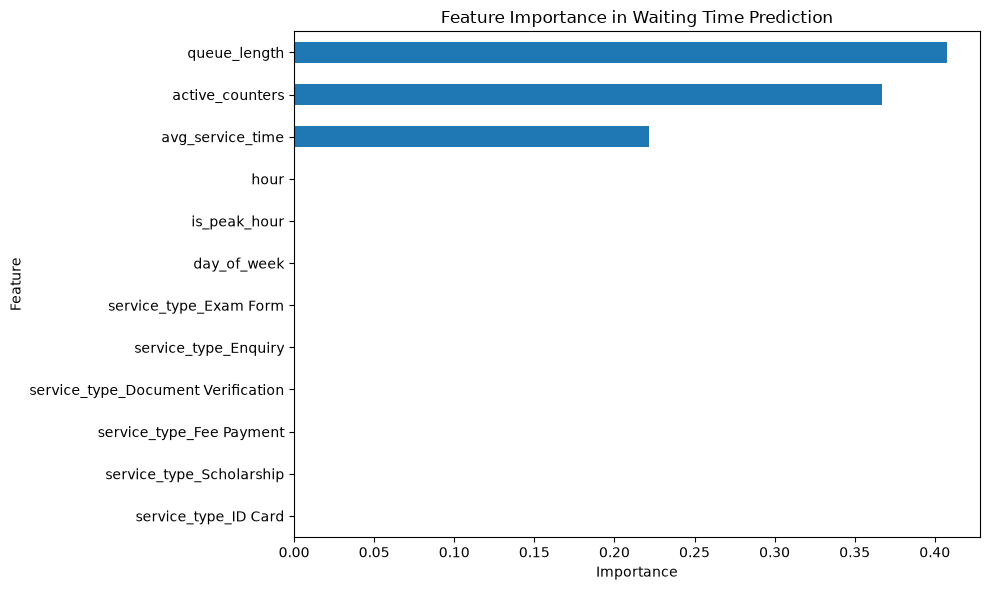

In [25]:
plt.figure(figsize=(10, 6))

feature_importance.sort_values().plot(kind="barh")

plt.title("Feature Importance in Waiting Time Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [26]:
feature_importance_df = feature_importance.reset_index()

feature_importance_df.columns = ["feature", "importance"]

feature_importance_df.to_csv(
    "../data/processed/feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [27]:
import joblib

feature_columns = X_train.columns.tolist()

joblib.dump(
    feature_columns,
    "../models/feature_columns.pkl"
)

print("Feature columns saved successfully!")
print(feature_columns)

Feature columns saved successfully!
['queue_length', 'active_counters', 'avg_service_time', 'hour', 'day_of_week', 'is_peak_hour', 'service_type_Document Verification', 'service_type_Enquiry', 'service_type_Exam Form', 'service_type_Fee Payment', 'service_type_ID Card', 'service_type_Scholarship']
